# Online Retail — Exploratory Data Analysis

## Project Overview

This project performs an exploratory data analysis of an Online Retail dataset to understand sales performance, customer behavior, product performance, geographical distribution, and sales trends over time.

### Objectives

- Clean and prepare the retail dataset
- Identify missing values and duplicate records
- Analyze returns and unusual transactions
- Calculate sales and key business metrics
- Identify top-performing products and customers
- Analyze sales across countries
- Identify monthly sales trends
- Detect and investigate potential outliers
- Generate actionable business insights and recommendations

### Key Business Questions

1. Which countries generate the most sales?
2. Which products generate the highest revenue?
3. Which products are sold in the highest quantities?
4. How do sales change over time?
5. Which customers generate the highest sales?
6. What is the typical transaction value?
7. Are there unusual or extreme transactions?

## Dataset Information

The dataset contains transactional records from an online retail business. Each row represents a product line within a customer invoice.

The analysis focuses on transaction dates, products, quantities, prices, customers, countries, and calculated sales values.

In [1]:
print("My EDA Project has Started")

My EDA Project has Started


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [8]:
df.duplicated().sum()

np.int64(5268)

In [9]:
df[df["CustomerID"].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [10]:
df[df["Description"].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [11]:
df[df.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [12]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

Original rows: 541909
Rows after removing duplicates: 536641


In [13]:
df_clean.duplicated().sum()

np.int64(0)

In [14]:
df_clean.shape

(536641, 8)

In [15]:
df_clean[df_clean["Quantity"] < 0].shape

(10587, 8)

In [16]:
df_clean[df_clean["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [17]:
df_clean[df_clean["InvoiceNo"].astype(str).str.startswith("C")].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [18]:
df_clean[df_clean["InvoiceNo"].astype(str).str.startswith("C")].shape

(9251, 8)

In [19]:
print("Positive quantity:", (df_clean["Quantity"] > 0).sum())
print("Negative quantity:", (df_clean["Quantity"] < 0).sum())
print("Zero quantity:", (df_clean["Quantity"] == 0).sum())

Positive quantity: 526054
Negative quantity: 10587
Zero quantity: 0


In [20]:
df_clean[df_clean["UnitPrice"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [21]:
df_clean[df_clean["UnitPrice"] < 0].shape

(2, 8)

In [22]:
df_clean[df_clean["UnitPrice"] == 0].shape

(2510, 8)

In [23]:
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

In [24]:
print("Original cleaned data:", len(df_clean))
print("Normal sales data:", len(sales_df))

Original cleaned data: 536641
Normal sales data: 524878


In [25]:
sales_df["SalesAmount"] = sales_df["Quantity"] * sales_df["UnitPrice"]

In [26]:
sales_df["SalesAmount"].describe()

,SalesAmount
count,524878.000000
mean,20.275399
std,271.693566
min,0.001000
25%,3.900000
50%,9.920000
75%,17.700000
max,168469.600000


In [27]:
sales_df.nlargest(10, "SalesAmount")[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "SalesAmount", "Country"]
]

,InvoiceNo,Description,Quantity,UnitPrice,SalesAmount,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
15017,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POSTAGE,1,8142.75,8142.75,United Kingdom
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
421601,573003,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


In [28]:
print("Total transactions:", sales_df["SalesAmount"].count())
print("Average sales amount:", round(sales_df["SalesAmount"].mean(), 2))
print("Median sales amount:", round(sales_df["SalesAmount"].median(), 2))

Total transactions: 524878
Average sales amount: 20.28
Median sales amount: 9.92


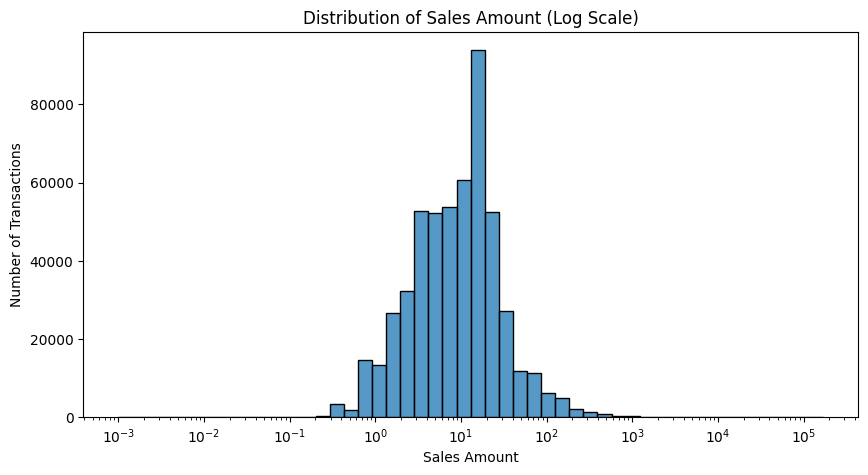

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(sales_df["SalesAmount"], bins=50, log_scale=True)

plt.title("Distribution of Sales Amount (Log Scale)")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Transactions")

plt.show()

# **Outlier Analysis**
The SalesAmount distribution is highly right-skewed. The median transaction value is £9.92, while the maximum transaction value reaches £168,469.60. Using the IQR method, transactions above £38.40 were identified as potential high-value outliers. However, these observations were retained because some represent legitimate bulk purchases rather than data errors. For example, the largest transaction involved 80,995 units of a product at £2.08 per unit

In [30]:
print(sales_df["SalesAmount"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

0.50         9.92
0.75        17.70
0.90        33.00
0.95        59.80
0.99       183.60
1.00    168469.60
Name: SalesAmount, dtype: float64


In [31]:
Q1 = sales_df["SalesAmount"].quantile(0.25)
Q3 = sales_df["SalesAmount"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier limit:", upper_limit)

Q1: 3.9
Q3: 17.700000000000003
IQR: 13.800000000000002
Upper outlier limit: 38.400000000000006


In [32]:
outliers = sales_df[sales_df["SalesAmount"] > upper_limit]

print("Number of potential outliers:", len(outliers))
print("Percentage of transactions:", round(len(outliers) / len(sales_df) * 100, 2), "%")

Number of potential outliers: 42624
Percentage of transactions: 8.12 %


In [33]:
outliers.nlargest(10, "SalesAmount")[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "SalesAmount", "Country"]
]

,InvoiceNo,Description,Quantity,UnitPrice,SalesAmount,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
15017,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POSTAGE,1,8142.75,8142.75,United Kingdom
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
421601,573003,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


## Sales Distribution by Country

This analysis examines total sales across countries to identify the markets contributing the most revenue.

In [34]:
country_sales = (
    sales_df.groupby("Country")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

,SalesAmount
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


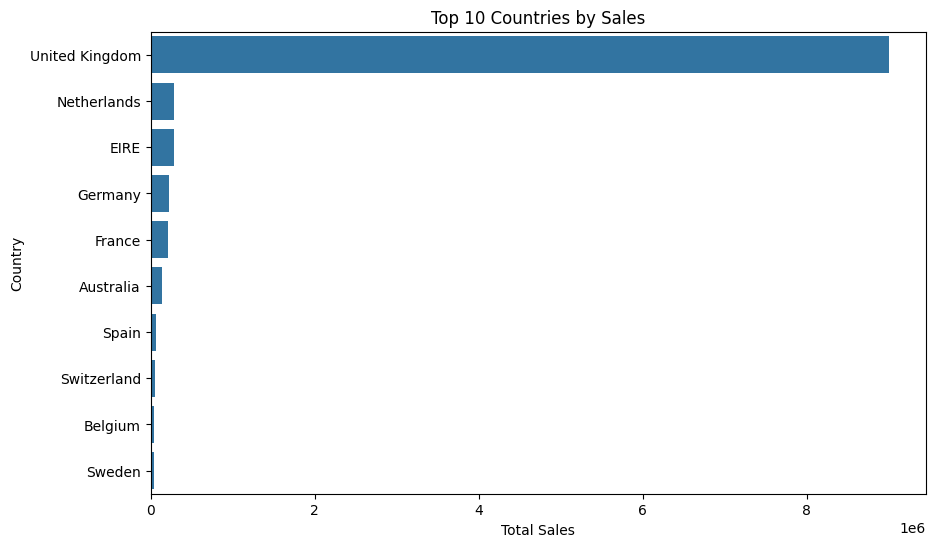

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_sales.head(10).values,
    y=country_sales.head(10).index
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")

plt.show()

# **Country Sales Insight**
The United Kingdom is the dominant market, generating approximately £9.0 million in sales, substantially higher than the Netherlands (£285.4K), EIRE (£283.1K), Germany (£228.7K), and France (£209.6K). This indicates that the business is heavily dependent on the UK market, while other European countries contribute considerably smaller amounts of revenue.

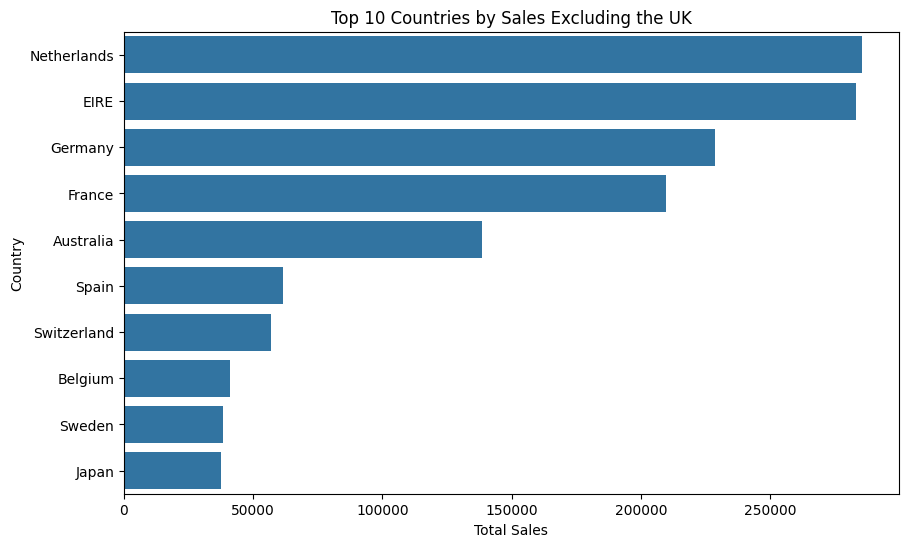

In [36]:
country_sales_without_uk = country_sales[country_sales.index != "United Kingdom"]

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_sales_without_uk.head(10).values,
    y=country_sales_without_uk.head(10).index
)

plt.title("Top 10 Countries by Sales Excluding the UK")
plt.xlabel("Total Sales")
plt.ylabel("Country")

plt.show()

## Product Performance

This section identifies the products generating the highest sales revenue and the products sold in the greatest quantities.

In [37]:
product_sales_df = sales_df[
    ~sales_df["Description"].str.contains(
        "AMAZON FEE|POSTAGE|Adjust bad debt",
        case=False,
        na=False
    )
].copy()

In [38]:
top_products = (
    product_sales_df.groupby("Description")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

top_products.head(10)

,SalesAmount
Description,
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,77752.82
RABBIT NIGHT LIGHT,66870.03
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59


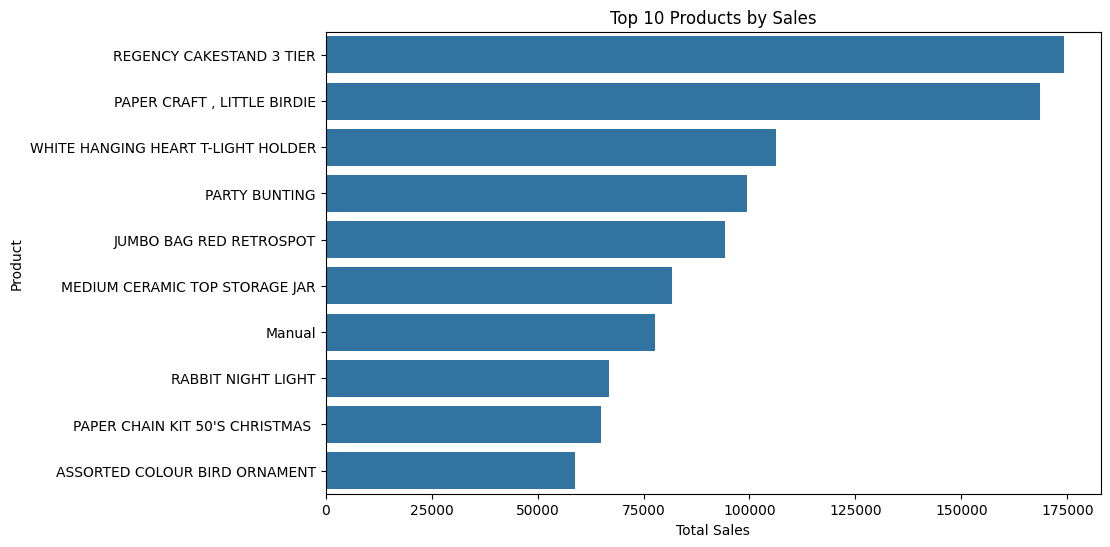

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.head(10).values,
    y=top_products.head(10).index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.show()

# Top Product Insight
REGENCY CAKESTAND 3 TIER generated the highest total sales at approximately £174K. PAPER CRAFT, LITTLE BIRDIE ranked second with approximately £168K; however, its high sales value is strongly influenced by an unusually large single transaction of 80,995 units. This demonstrates the importance of investigating outliers before interpreting product performance.

# Quantity Analysis
PAPER CRAFT, LITTLE BIRDIE has the highest recorded quantity sold at 80,995 units. However, this result is heavily influenced by an unusually large single transaction identified during outlier analysis. Therefore, quantity-based rankings should be interpreted alongside transaction-level analysis rather than being treated as a direct measure of consistent product demand.

In [40]:
top_quantity_products = (
    product_sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

top_quantity_products.head(10)

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


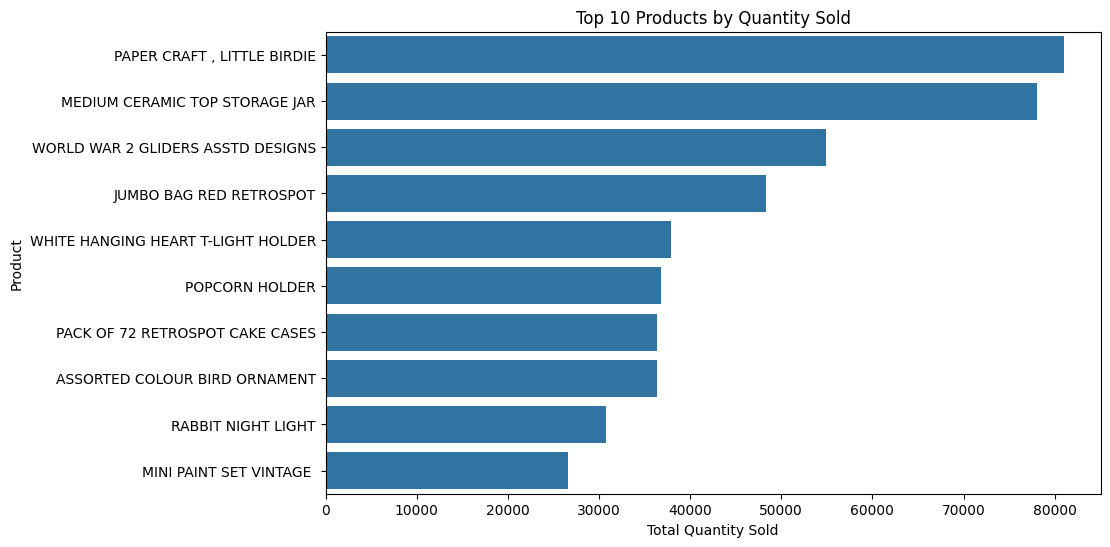

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_quantity_products.head(10).values,
    y=top_quantity_products.head(10).index
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.show()

## Sales Trends Over Time

Monthly sales and transaction volumes are analyzed to identify seasonal patterns and changes in business activity.

In [42]:
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

In [43]:
sales_df["InvoiceDate"].dtype

dtype('<M8[ns]')

In [44]:
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

In [45]:
monthly_sales = (
    sales_df.groupby("Month")["SalesAmount"]
    .sum()
)

monthly_sales

,SalesAmount
Month,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


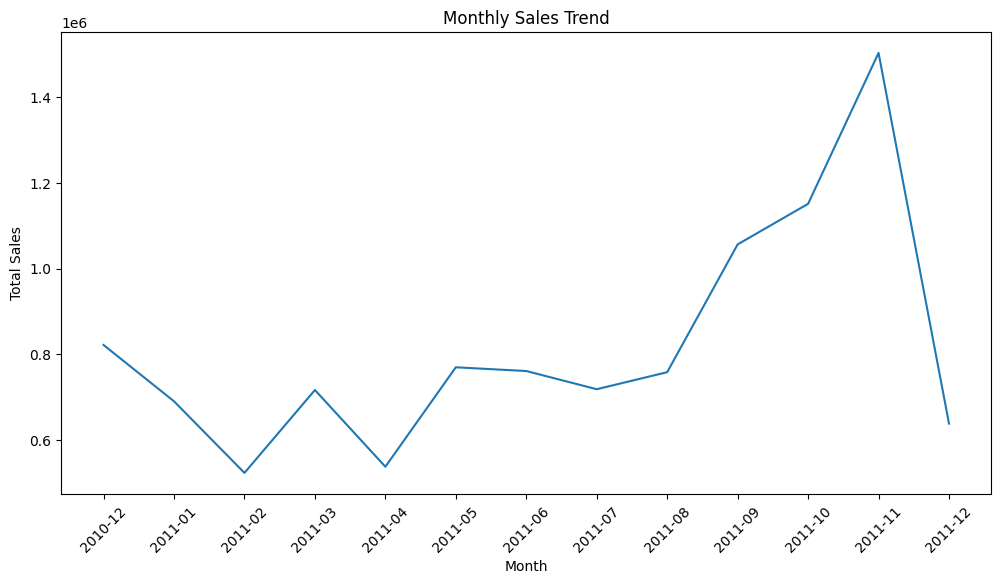

In [46]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.show()

# Monthly Sales Insight
Sales varied considerably across the analyzed period. November 2011 recorded the highest monthly sales at approximately £1.50 million, while February 2011 recorded the lowest at approximately £522.55 thousand. Total sales across the analyzed transactions were approximately £10.64 million, with average monthly sales of approximately £818.62 thousand.

In [47]:
print("Highest sales month:")
print(monthly_sales.idxmax(), "→", round(monthly_sales.max(), 2))

print("\nLowest sales month:")
print(monthly_sales.idxmin(), "→", round(monthly_sales.min(), 2))

Highest sales month:
2011-11 → 1503866.78

Lowest sales month:
2011-02 → 522545.56


In [48]:
print("Total sales:", round(sales_df["SalesAmount"].sum(), 2))
print("Average monthly sales:", round(monthly_sales.mean(), 2))

Total sales: 10642110.8
Average monthly sales: 818623.91


In [49]:
monthly_transactions = (
    sales_df.groupby("Month")["InvoiceNo"]
    .nunique()
)

In [50]:
monthly_transactions

,InvoiceNo
Month,
2010-12,1559
2011-01,1086
2011-02,1100
2011-03,1454
2011-04,1246
2011-05,1681
2011-06,1533
2011-07,1475
2011-08,1361


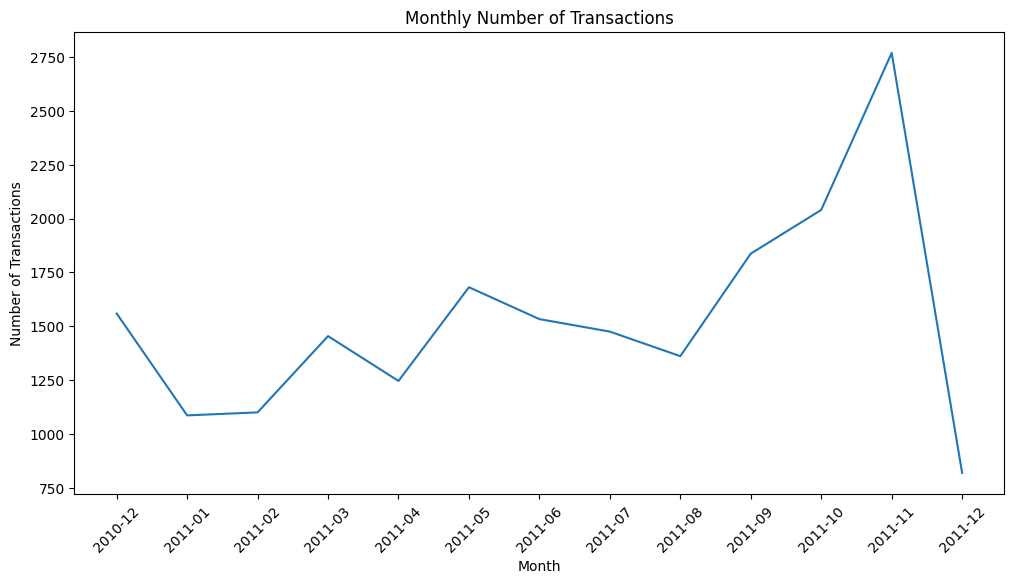

In [51]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_transactions.index.astype(str),
    monthly_transactions.values
)

plt.title("Monthly Number of Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.show()

# Transaction Volume Insight
 November 2011 recorded the highest number of transactions, with 2,769 unique invoices, and also recorded the highest monthly sales. December 2011 had the lowest transaction volume, with 819 unique invoices. This suggests that transaction volume was an important contributor to the November sales peak.

In [52]:
print("Highest transaction month:")
print(monthly_transactions.idxmax(), "→", monthly_transactions.max())

print("\nLowest transaction month:")
print(monthly_transactions.idxmin(), "→", monthly_transactions.min())

Highest transaction month:
2011-11 → 2769

Lowest transaction month:
2011-12 → 819


## Customer Analysis

This analysis identifies high-value customers based on their total sales contribution.

In [53]:
customer_sales_df = sales_df.dropna(subset=["CustomerID"]).copy()

In [54]:
top_customers = (
    customer_sales_df.groupby("CustomerID")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

top_customers.head(10)

,SalesAmount
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


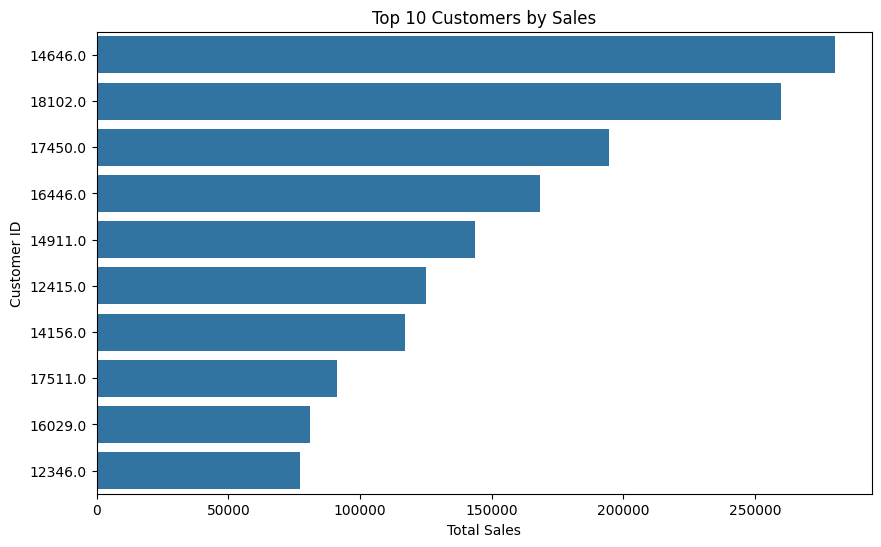

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_customers.head(10).values,
    y=top_customers.head(10).index.astype(str)
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer ID")

plt.show()

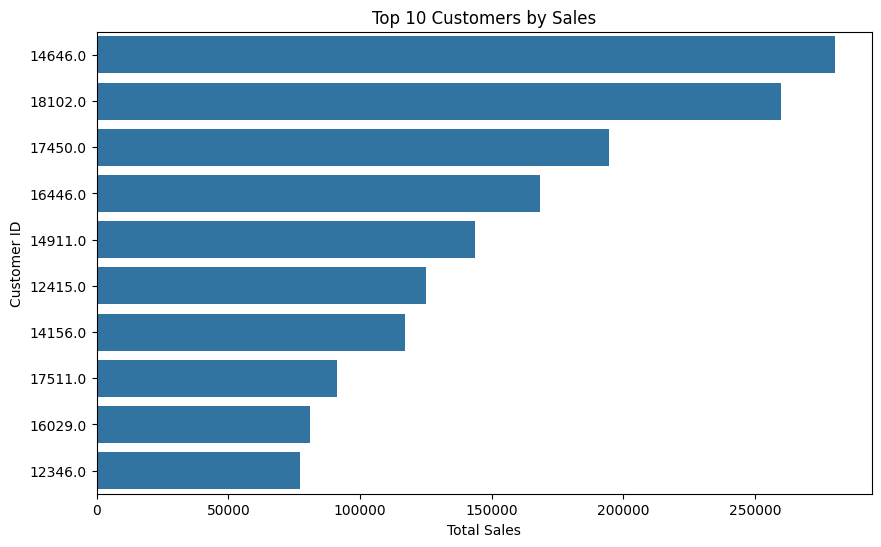

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_customers.head(10).values,
    y=top_customers.head(10).index.astype(str)
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer ID")

plt.show()

# Customer Sales Insight
Customer 14646 generated the highest recorded sales at approximately £280K, followed by Customer 18102 at approximately £260K. The results indicate that a relatively small group of customers contributes substantial sales revenue, highlighting the importance of identifying and retaining high-value customers.

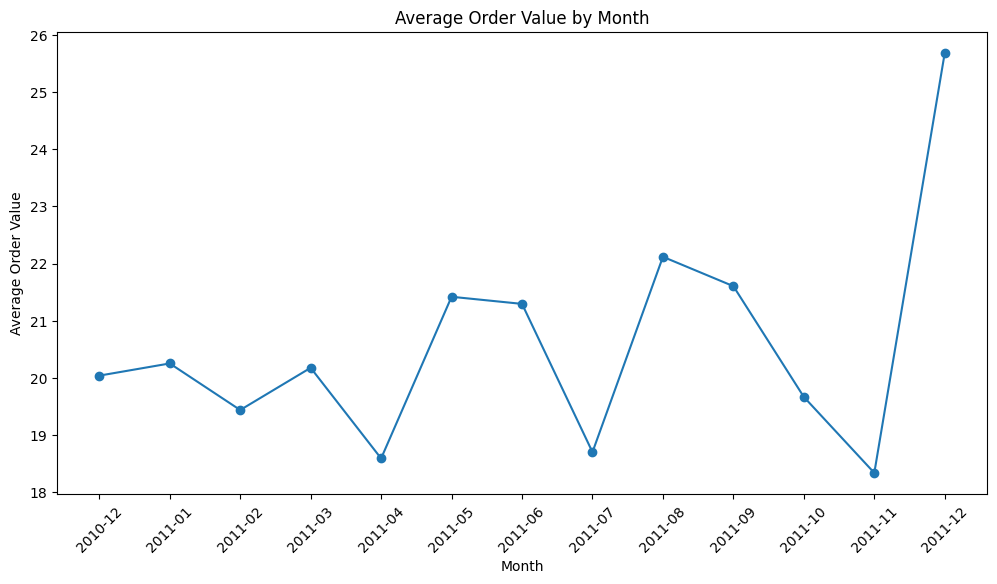

In [57]:
monthly_avg_order = (
    sales_df.groupby("Month")["SalesAmount"]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg_order.index.astype(str),
    monthly_avg_order.values,
    marker="o"
)

plt.title("Average Order Value by Month")
plt.xlabel("Month")
plt.ylabel("Average Order Value")

plt.xticks(rotation=45)

plt.show()

### Insight

Average transaction value remained relatively stable across most months but increased sharply in December 2011. This suggests that although December had fewer transactions, the average value of each transaction was substantially higher.

In [58]:
average_order_value = sales_df["SalesAmount"].mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 20.28


In [59]:
average_quantity = sales_df["Quantity"].mean()

print("Average Quantity per Transaction:", round(average_quantity, 2))

Average Quantity per Transaction: 10.62


In [60]:
unique_customers = sales_df["CustomerID"].nunique()

print("Unique Customers:", unique_customers)

Unique Customers: 4338


In [61]:
print("Total Sales:", round(sales_df["SalesAmount"].sum(), 2))
print("Total Transactions:", sales_df["InvoiceNo"].nunique())
print("Unique Products:", sales_df["Description"].nunique())
print("Unique Countries:", sales_df["Country"].nunique())

Total Sales: 10642110.8
Total Transactions: 19960
Unique Products: 4026
Unique Countries: 38


## Business Recommendations

Based on the exploratory data analysis, the following recommendations can be made:

1. **Strengthen the UK market:**  
   The United Kingdom contributes the majority of sales. The business should continue strengthening its UK customer base while maintaining strong customer service and product availability.

2. **Expand international markets:**  
   Countries such as the Netherlands, EIRE, Germany, France, and Australia show meaningful sales potential. Targeted marketing campaigns could help increase sales in these markets.

3. **Focus on high-performing products:**  
   Products such as REGENCY CAKESTAND 3 TIER and WHITE HANGING HEART T-LIGHT HOLDER generate strong revenue. These products should receive continued attention in inventory planning and promotions.

4. **Investigate high-value transactions:**  
   Extremely large transactions can significantly influence overall sales and product rankings. These transactions should be monitored separately to distinguish genuine bulk orders from potential data-quality issues.

5. **Retain high-value customers:**  
   A small number of customers contribute substantial revenue. Loyalty programs, personalized offers, and targeted customer retention strategies could help maintain these valuable relationships.

6. **Use monthly trends for planning:**  
   Sales and transaction volumes vary across months. Historical monthly trends can be used to improve inventory planning, marketing campaigns, and seasonal sales strategies.

## Conclusion

This exploratory data analysis provided insights into the sales performance
products, customers, countries, and time-based trends within the Online Retail dataset.

The analysis identified approximately £10.64 million in sales across 19,960 unique transactions, 4,026 products, 38 countries, and 4,338 identifiable customers. The United Kingdom was the dominant market, while November 2011 recorded the highest monthly sales.

The analysis also identified significant outliers in transaction values. Rather than automatically removing these observations, they were investigated and retained because some represented genuine bulk purchases.

Overall, the analysis demonstrates how data cleaning, statistical analysis, visualization, and business interpretation can be combined to identify meaningful patterns and support data-driven decision-making.






## Key Performance Indicators (KPIs)

| KPI | Value |
|---|---:|
| **Total Sales** | **£10,642,110.80** |
| **Total Transactions** | **19,960** |
| **Unique Products** | **4,026** |
| **Unique Countries** | **38** |
| **Unique Customers** | **4,338** |
| **Average Transaction Value** | **£20.28** |
| **Average Quantity per Transaction** | **10.62 units** |

### KPI Summary

The analysis covers approximately **£10.64 million in sales** across **19,960 unique transactions**, involving **4,026 products**, **38 countries**, and **4,338 identifiable customers**. The average transaction value was **£20.28**, with an average of **10.62 units per transaction**.